# Chapter 14 — Wheels and satellites

Companion notebook to **Chapter 14**: differential-drive odometry and its drift, the wheel factor, geodetic and ENU
coordinates, the GNSS factor with its lever arm, the 4-DoF alignment and its accuracy, and a short VIO + wheels + GNSS
run. `examples/ch14_fusion.py` runs the full experiments.

In [1]:
import sys
from pathlib import Path

ROOT = Path.cwd().parent            # the code/ directory
sys.path[:0] = [str(ROOT), str(ROOT / "examples")]

import numpy as np
import matplotlib.pyplot as plt
from vslam import fusion, imu, lie, robust, sim, vio
from ch13_vio import setup, errors
from ch14_fusion import sensors, run, LEVER, ENC_RATE

np.set_printoptions(precision=4, suppress=True)
rng = np.random.default_rng(0)
# after the imports: the example scripts select the Agg backend
%matplotlib inline

## 1. Differential drive: heading drift from a radius mismatch (Definition 14.1, equation 14.3)

distance 65.4 m; predicted heading error -67.4 deg, measured -67.9 deg (slip in the turns adds a little)


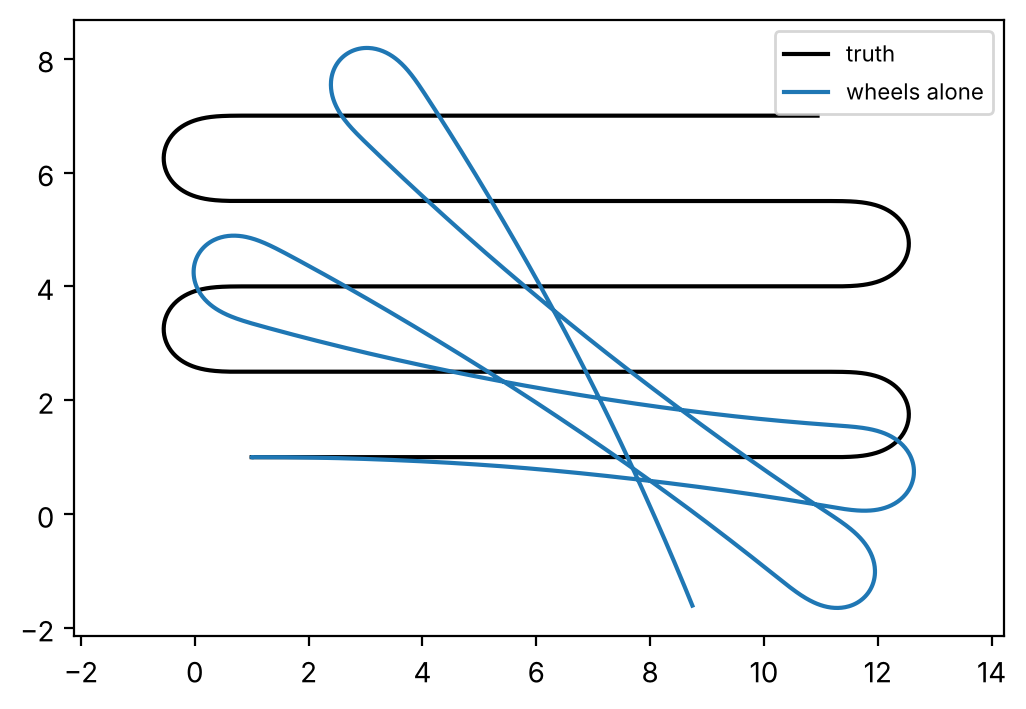

In [2]:
m = sim.GardenMotion()
sens = sensors(m)
v_e, w_e = fusion.diff_drive(sens["vl"], sens["vr"], sens["enc"].track)
psi0 = np.arctan2(m.R(0)[1, 0], m.R(0)[0, 0])
odo, _ = fusion.dead_reckon_2d(v_e, w_e, 1 / ENC_RATE, (m.p(0)[0], m.p(0)[1], psi0))
enc = sens["enc"]
D = np.sum(np.abs(sens["vw"][:, 0])) / ENC_RATE
pred = (enc.scale_r - enc.scale_l) * D / enc.track
psi_t = np.unwrap([np.arctan2(m.R(t)[1, 0], m.R(t)[0, 0]) for t in sens["te"]])
print(f"distance {D:.1f} m; predicted heading error {np.degrees(pred):.1f} deg, "
      f"measured {np.degrees(odo[-2, 2] - psi_t[-1]):.1f} deg (slip in the turns adds a little)")
gt = np.array([m.p(t) for t in sens["te"]])
plt.figure(figsize=(6, 4)); plt.plot(gt[:, 0], gt[:, 1], "k", label="truth")
plt.plot(odo[:, 0], odo[:, 1], label="wheels alone"); plt.axis("equal"); plt.legend(fontsize=8)

## 2. Dead-reckoning covariance (Proposition 14.2)

In [3]:
n, dt = 500, 0.02
v, w = np.full(n, 1.0), np.full(n, 0.2)
x, P = fusion.dead_reckon_2d(v, w, dt, sigma_v=0.05, sigma_w=0.02)
ends = []
for _ in range(1000):
    xn, _ = fusion.dead_reckon_2d(v + rng.normal(0, 0.05 / np.sqrt(dt), n),
                                  w + rng.normal(0, 0.02 / np.sqrt(dt), n), dt)
    ends.append(xn[-1] - x[-1])
print("std x, y, yaw  propagated:", np.sqrt(np.diag(P[-1])))
print("               Monte Carlo:", np.std(ends, axis=0))

std x, y, yaw  propagated: [0.3253 0.168  0.0632]
               Monte Carlo: [0.3239 0.1692 0.0633]


## 3. The factors (Propositions 14.3 and 14.5): Jacobians against finite differences

In [4]:
s = vio.KFState(lie.so3_exp(rng.normal(0, 0.3, 3)), rng.normal(0, 1, 3), rng.normal(0, 2, 3), np.zeros(3), np.zeros(3))
for f in [fusion.WheelFactor(0.9), fusion.GnssFactor(np.zeros(3), [0.015, 0.015, 0.03], LEVER)]:
    r0, J = f(s)
    num = np.column_stack([(f(vio.boxplus(s, e))[0] - r0) / 1e-6 for e in 1e-6 * np.eye(15)])
    print(type(f).__name__, "max |analytic - numeric|:", np.abs(num - J).max())

WheelFactor max |analytic - numeric|: 2.1809980445652855e-05
GnssFactor max |analytic - numeric|: 2.3997595482327938e-05


## 4. Geodesy (Proposition 14.4)

A local ENU frame at an arbitrary reference point (45° N, 7° E): conversions both ways.

In [5]:
F = fusion.LocalFrame(np.radians(45.0), np.radians(7.0), 250.0)
p = np.array([10.0, 5.0, 0.3])
lat, lon, h = F.to_geodetic(p)
print(f"ENU {p} -> lat {np.degrees(lat):.8f}, lon {np.degrees(lon):.8f}, h {h:.3f}")
print("and back:", F.to_enu(lat, lon, h))
print("1 m north is", 1 / (np.radians(1) * 6.37e6) * 3600, "arcseconds of latitude")

ENU [10.   5.   0.3] -> lat 45.00004499, lon 7.00012682, h 250.300
and back: [10.   5.   0.3]
1 m north is 0.032380660321365204 arcseconds of latitude


## 5. Heading from a straight drive (Propositions 14.6 and 14.7)

Monte Carlo of the 4-DoF alignment on fixes along a straight line, against $\sigma\sqrt{12}/(L\sqrt n)$.

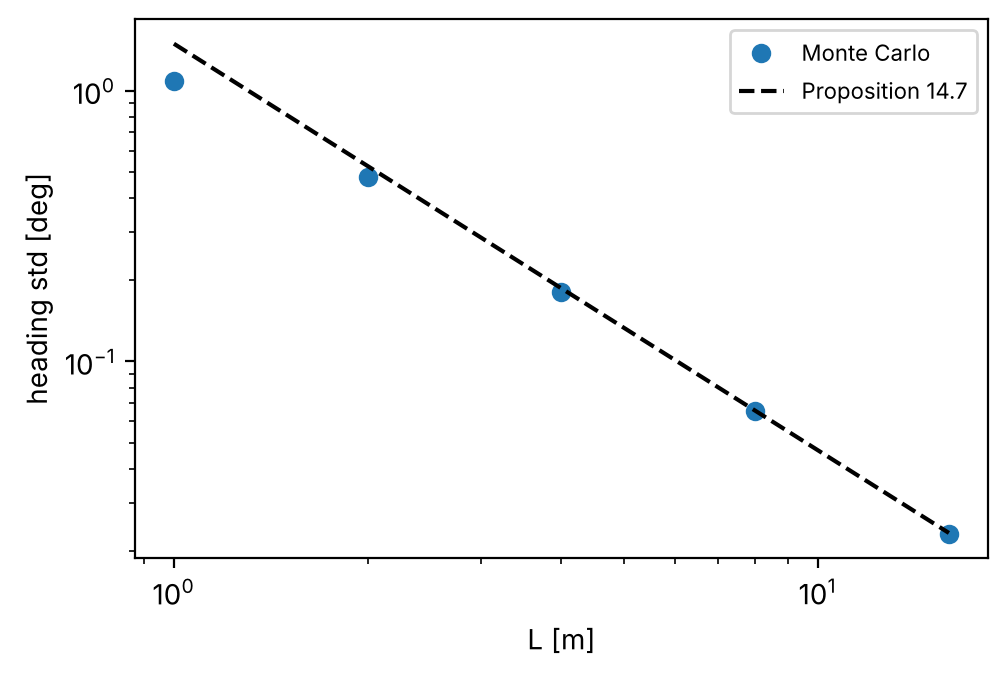

In [6]:
sigma, Ls = 0.015, np.array([1, 2, 4, 8, 16])
sd, th = [], []
for L in Ls:
    nfix = int(4 * L)
    a = np.column_stack([np.linspace(0, L, nfix), np.zeros(nfix), np.zeros(nfix)])
    yaws = []
    for _ in range(500):
        b = a @ lie.so3_exp(np.array([0, 0, 0.4])).T + np.array([2.0, 1.0, 0]) + rng.normal(0, sigma, a.shape)
        yaws.append(fusion.align_4dof(a, b)[0] - 0.4)
    sd.append(np.degrees(np.std(yaws))); th.append(np.degrees(sigma * np.sqrt(12) / (L * np.sqrt(nfix))))
plt.figure(figsize=(5.5, 3.5)); plt.loglog(Ls, sd, "o", label="Monte Carlo"); plt.loglog(Ls, th, "k--", label="Proposition 14.7")
plt.xlabel("L [m]"); plt.ylabel("heading std [deg]"); plt.legend(fontsize=8)

## 6. VIO + wheels + GNSS on the first 25 s

The receiver loses the fix under the young tree (from about 6 s) and near the house; the Cauchy kernel handles the
multipath outliers.

VIO                        RMS 2.1 cm, max 6.0 cm


VIO + wheels + GNSS        RMS 0.7 cm, max 1.4 cm


VIO + GNSS, no lever arm   RMS 7.5 cm, max 23.9 cm


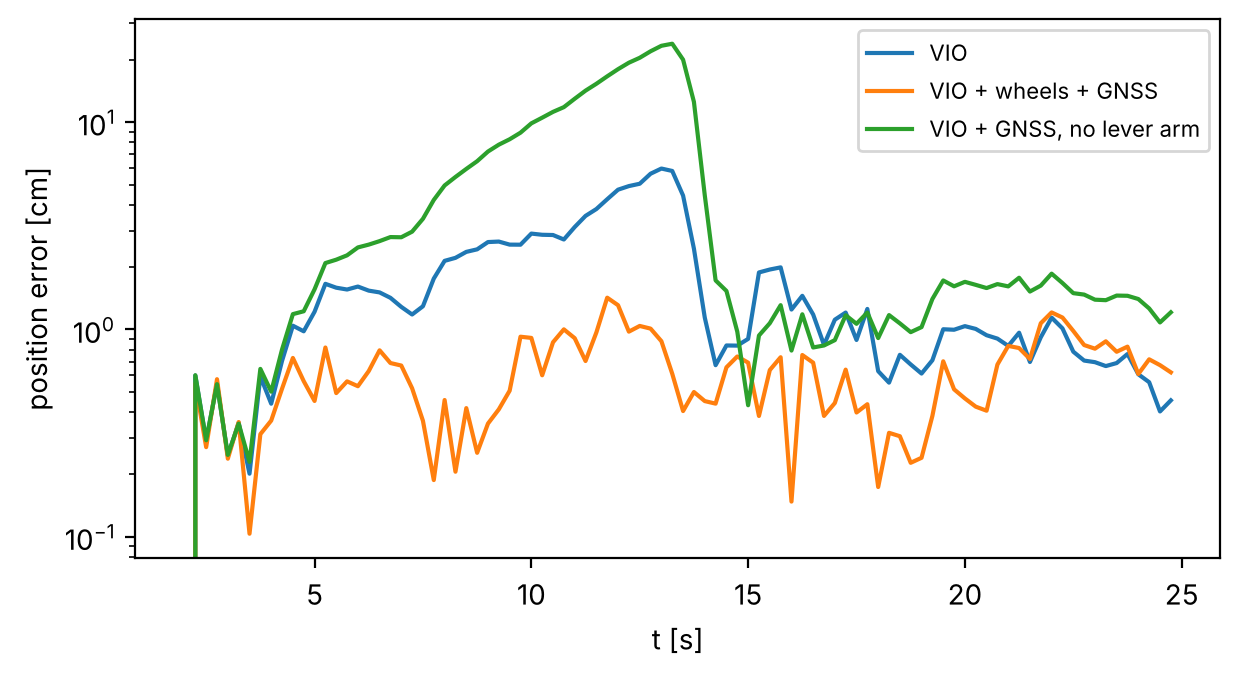

In [7]:
m, P, data, S, Tbc, ts, frames = setup()
short = frames[:int(25 * 20)]
res = {}
for name, kw in [("VIO", {}), ("VIO + wheels + GNSS", dict(wheels=True, gnss="cauchy")),
                 ("VIO + GNSS, no lever arm", dict(gnss="cauchy", lever=np.zeros(3)))]:
    _, est = run(m, P, data, S, Tbc, ts[:len(short)], short, sens, **kw)
    e, _, _ = errors(m, [(t, s.R, s.p) for t, s in est])
    res[name] = (np.array([t for t, _ in est]), e)
    print(f"{name:26s} RMS {100 * np.sqrt(np.mean(e**2)):.1f} cm, max {100 * e.max():.1f} cm")
plt.figure(figsize=(7, 3.5))
for name, (t, e) in res.items():
    plt.semilogy(t, 100 * e, label=name)
plt.xlabel("t [s]"); plt.ylabel("position error [cm]"); plt.legend(fontsize=8)

## Exercises

1. Add a wheel scale factor to the estimation: how would you include it in the state, and what makes it observable?
2. Reduce the GNSS outliers' probability to 0 and compare least squares with the Cauchy kernel again.
3. Move the antenna to the body origin (`LEVER = 0` in the simulation and in the factor) and check that the
   no-lever-arm error disappears.